Evan C. Mayer

2026-10-09

This notebook attempts to model the power landing on our detectors in the flight cryostat under various lab configurations. Assumptions and known omissions are littered throughout the notebook.

In [56]:
import matplotlib.pyplot as plt
import numpy as np

from astropy import constants as c
from astropy import units as u
from astropy.modeling.models import BlackBody

from astropy.visualization import quantity_support
quantity_support()

import pandas as pd

from scipy.interpolate import interp1d

RADIUS_FEEDHORN = 1.1 * u.mm
w0_FEEDHORN = RADIUS_FEEDHORN * 0.644 # Goldsmith

In [57]:
# # Chicago TeraFlash data does not support much below ~68 um...transmission goes > 1.
lambd = np.linspace(68, 500, num=3000) * u.um

# inband = (lambd > 317 * u.um) & (lambd < (420 * u.um))
# lambd = lambd[inband]

/home/evanmayer/miniconda3/envs/astr-new/lib/python3.11/site-packages/astropy/units/quantity.py:658: RuntimeWarning: divide by zero encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)


(68.0, 500.0)

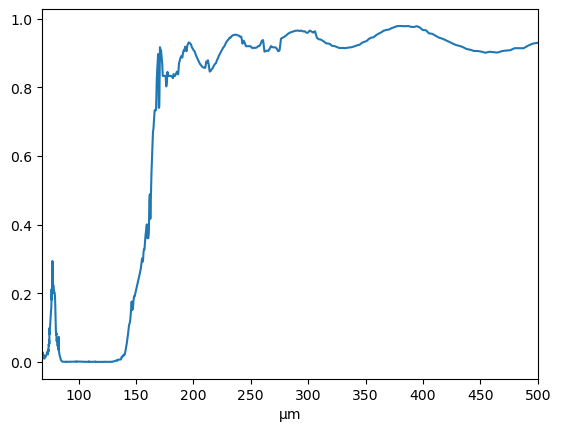

In [58]:
# Cardiff filter data
name_to_fname = {
    'c7p5_shader': './Cardiff_TIM_202505/202505_P34507_P34508_C7.5.tsv',
    'VCS2_st': './Cardiff_TIM_202505/202505_FP3373ARC_VCS2_T1934R13.tsv',
    'VCS1_st': './Cardiff_TIM_202505/202505_FP3464ARC_VCS1_T1947R19.tsv',
    '100icm_lpe': './Cardiff_TIM_202505/202505_FP3311ARC_100icm_T1947R22.tsv',
    '33icm_lpe': './Cardiff_TIM_202505/202505_FP3315_33icm_T1929R9.tsv',
    '42icm_lpe': './Cardiff_TIM_202505/202505_FP3316_42icm_T1929R5.tsv',
    '60icm_lpe': './Cardiff_TIM_202505/202505_FP3480ARC_65icm_T1947R13.tsv'
}
def bandpass_from_file(fname, usecols=[0, 1]):
    '''
    return function to return interpolated values over wavelength from file.
    requested values outside of range are 0 on short wave side and 1 on long wave side.
    '''
    df = pd.read_csv(fname, sep='\t', usecols=usecols, skiprows=1, names=['k_icm', 'T_ul'])
    lambd_um = 10000. * u.um / df['k_icm'].values
    interper = interp1d(lambd_um[::-1], df['T_ul'][::-1].values, bounds_error=False, fill_value=(0.0, 1.0))
    return interper

# Chicago filter data
tf_base = './TIM-TeraFlash-main/20260803/calibrated/'
tf_ext = '.csv'
name_to_fname_teraflash = {
    'HDPE_window': tf_base + 'HDPE_window' + tf_ext,
    'c7p5_shader': tf_base + 'vcs2_shader' + tf_ext,
    'c7p5_shader_1': tf_base + '300K' + tf_ext,
    'VCS2_st': tf_base + 'vcs2_0' + tf_ext,
    'VCS1_st': tf_base + 'vcs1_0' + tf_ext,
    '100icm_lpe': tf_base + '4K_0' + tf_ext,
    # no 33 icm data
    '42icm_lpe': tf_base + 'LPE_42icm' + tf_ext,
    '60icm_lpe': tf_base + 'LPE_65icm' + tf_ext,
}
def bandpass_from_file_teraflash(fname):
    '''For reading Alex T. TeraFlash data files'''
    df = pd.read_csv(fname)
    freq_ghz = df['frequency_GHz'].values * u.GHz
    lambd_um = (c.c / freq_ghz).to(u.um)
    transmission = df['ut'].values
    transmission[transmission > 1] = 1
    interper = interp1d(lambd_um, df['ut'].values, bounds_error=False, fill_value=(0.0, 1.0))
    return interper

def bandpass_from_xlsx(fname):
    '''For reading grating efficiency excel files'''
    df = pd.read_excel(fname, skiprows=1)
    lambd_um = df['Wavelength'].values * u.um
    transmission = df['UnPol'].values
    interper = interp1d(lambd_um, transmission, bounds_error=False, fill_value=(0.0, 1.0))
    return interper

fig, ax = plt.subplots()
ax.plot(lambd, bandpass_from_file_teraflash(name_to_fname_teraflash['VCS1_st'])(lambd))
ax.set_xlim(68 * u.um, 500 * u.um)

Show the measured filter bandpasses from the Chicago measurement campaign. I omit the porous polypropylene scattering filter here because the transmission is quite high so I am neglecting it.

This accounting of efficiency does not assume any spill at any surface. The most important omission here is probably the slit.

/home/evanmayer/miniconda3/envs/astr-new/lib/python3.11/site-packages/astropy/units/quantity.py:658: RuntimeWarning: divide by zero encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/home/evanmayer/miniconda3/envs/astr-new/lib/python3.11/site-packages/astropy/units/quantity.py:658: RuntimeWarning: divide by zero encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/home/evanmayer/miniconda3/envs/astr-new/lib/python3.11/site-packages/astropy/units/quantity.py:658: RuntimeWarning: divide by zero encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/home/evanmayer/miniconda3/envs/astr-new/lib/python3.11/site-packages/astropy/units/quantity.py:658: RuntimeWarning: divide by zero encountered in divide
  result = super().__array_ufunc__(function, method, *arrays, **kwargs)
/home/evanmayer/miniconda3/envs/astr-new/lib/python3.11/site-packages/astropy/units/quantity.py:

Text(0.5, 1.0, 'Bandpasses')

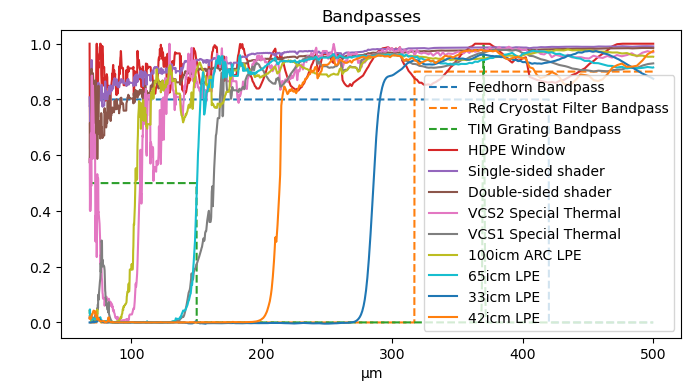

In [59]:
def bandpass_feedhorn_lw(lambd):
    # coarse feedhorn cutoff behavior: absorber efficiency and feedhorn waveguide losses
    # ~0.9 absorber efficiency, ~0.8 total efficiency...the difference would be horns
    return np.piecewise(lambd, [lambd <= 420 * u.um, lambd > 420 * u.um], [.8, 0])

def bandpass_red_filter(lambd, amplitude=0.9):
    # coarse JPL red cryostat filter stack behavior
    return np.piecewise(lambd, [lambd > 317 * u.um, lambd <= 317 * u.um], [amplitude, 0])

def bandpass_spec_channel(lambd, lambd_center, resolving_power=250, amplitude=1.0, leaky=True):
    std_dev = lambd_center / 2.355 / resolving_power
    coeff = 1. # 1. / (std_dev * np.sqrt(2. * np.pi))
    ret = lambda x: amplitude * coeff * np.exp(-.5 * (x - lambd_center) ** 2 / std_dev ** 2)
    if not leaky:
        return ret(lambd)
    else:
        # if simulating leaky behavior, consider that gratings can pass more
        # than just the intended order. order-sorting filters are SUPPOSED to
        # make this impossible, but in general the free spectral range (the
        # wavelength separation between adjacent orders landing at the same
        # angle) is \Delta \lambda = \lambda / m. Start "turning on" grating
        # efficiency for LW array at lambda / 2 ~ 150 um.
        return np.piecewise(
            lambd,
            [lambd < 150 * u.um, lambd >= 150 * u.um],
            [0.5, ret]
        )

fig, ax = plt.subplots(figsize=(8,4))
ax.plot(lambd, bandpass_feedhorn_lw(lambd), ls='--', label='Feedhorn Bandpass')
ax.plot(lambd, bandpass_red_filter(lambd), ls='--', label='Red Cryostat Filter Bandpass')
ax.plot(lambd, bandpass_spec_channel(lambd, 370 * u.um), ls='--', label='TIM Grating Bandpass')

bp_hdpe = bandpass_from_file_teraflash(name_to_fname_teraflash['HDPE_window'])(lambd)
bp_c7p5_single = bandpass_from_file_teraflash(name_to_fname_teraflash['c7p5_shader_1'])(lambd)
bp_c7p5_double = bandpass_from_file_teraflash(name_to_fname_teraflash['c7p5_shader'])(lambd)
bp_VCS2_st = bandpass_from_file_teraflash(name_to_fname_teraflash['VCS2_st'])(lambd)
bp_VCS1_st = bandpass_from_file_teraflash(name_to_fname_teraflash['VCS1_st'])(lambd)
bp_100icm = bandpass_from_file_teraflash(name_to_fname_teraflash['100icm_lpe'])(lambd)
bp_60icm = bandpass_from_file_teraflash(name_to_fname_teraflash['60icm_lpe'])(lambd)
bp_33icm = bandpass_from_file(name_to_fname['33icm_lpe'])(lambd)
bp_42icm = bandpass_from_file_teraflash(name_to_fname_teraflash['42icm_lpe'])(lambd)

ax.plot(lambd, bp_hdpe, label='HDPE Window')
ax.plot(lambd, bp_c7p5_single, label='Single-sided shader')
ax.plot(lambd, bp_c7p5_double, label='Double-sided shader')
ax.plot(lambd, bp_VCS2_st, label='VCS2 Special Thermal')
ax.plot(lambd, bp_VCS1_st, label='VCS1 Special Thermal')
ax.plot(lambd, bp_100icm, label='100icm ARC LPE')
ax.plot(lambd, bp_60icm, label='65icm LPE')
ax.plot(lambd, bp_33icm, label='33icm LPE')
ax.plot(lambd, bp_42icm, label='42icm LPE')
# ax.plot(lambd, bp_hdpe * bp_c7p5_double * bp_c7p5_single * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm, label='all filters')
ax.legend()
ax.set_title('Bandpasses')
# ax.set_xscale('log')
# ax.set_yscale('log')
# ax.set_xlim(68, 500)
# ax.set_ylim(1e-4, 1.1)

Recreate JPL's plot of blackbody temperature vs. power incident on detectors

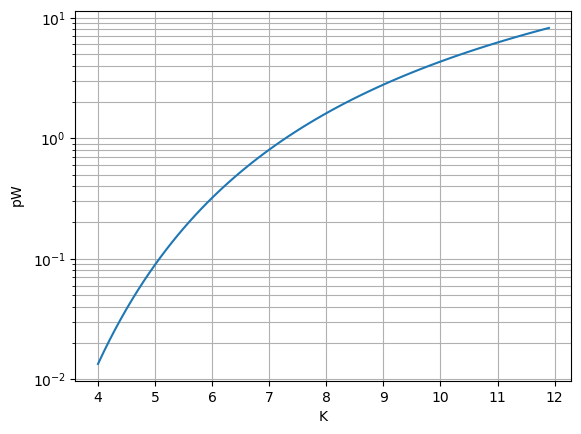

In [60]:
eps = 1
area = np.pi * RADIUS_FEEDHORN ** 2
coeff_solid_angle = 1 * u.sr / 2. / np.pi / w0_FEEDHORN ** 2

temps = np.arange(4, 12, 0.1) * u.K

powers = []
for T_bb in temps:
    power = eps * area * coeff_solid_angle * np.trapezoid(bandpass_feedhorn_lw(lambd) * bandpass_red_filter(lambd) * BlackBody(T_bb, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) * (lambd ** 2), lambd)
    powers.append(power.to(u.pW).value)

from matplotlib.ticker import AutoMinorLocator
fig, ax = plt.subplots()
ax.plot(temps, np.array(powers) * u.pW)
ax.grid(which='both')
ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.set_yscale('log')

Overplot the TIM cryostat version: consider the grating and STARFIRE filters

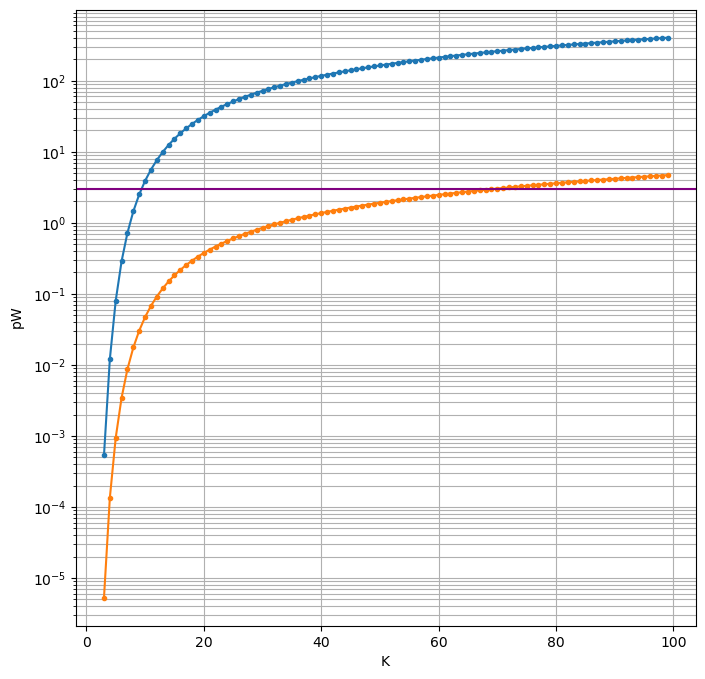

In [61]:
center_lambd = 370 * u.um

eps = 1 # assume perfect blackbody source outside filter stack
area = np.pi * RADIUS_FEEDHORN**2
coeff_solid_angle = 1 * u.sr / 2. / np.pi / w0_FEEDHORN ** 2
temps = np.arange(3, 100, 1) * u.K

powers = []
powers_tim = []

eff_blaze_grating = 0.78

for T_bb in temps:
    power_red = eps * area * coeff_solid_angle * np.trapezoid(
        bandpass_feedhorn_lw(lambd) *
        bandpass_red_filter(lambd)**2 *
        BlackBody(T_bb, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
        (lambd ** 2),
        lambd
    )
    powers.append(power_red.to(u.pW).value)

    power_tim = eps * area * coeff_solid_angle * np.trapezoid(
        bandpass_feedhorn_lw(lambd) *
        bandpass_spec_channel(lambd, center_lambd) *
        bp_hdpe * bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_42icm * bp_33icm * eff_blaze_grating *
        BlackBody(T_bb, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
        (lambd ** 2),
        lambd
    )
    powers_tim.append(power_tim.to(u.pW).value)

powers = np.array(powers)
powers_tim = np.array(powers_tim)

from matplotlib.ticker import AutoMinorLocator
fig, ax = plt.subplots(figsize=(8,8))
ax.plot(temps, powers * u.pW, marker='.')
ax.plot(temps, powers_tim * u.pW, marker='.')
ax.grid(which='both')
ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.set_yscale('log')
# df/f in TIM cryostat, when looking at filters with mirror plate, is ~-0.0005
# to -0.0006.
# in RED, this would be ~3-4 pW on the detector.
# Drawing a line over to the contour of power seen by a TIM detector for the
# same BB input, we see that in order to deliver a similar df/f to the detector,
# i.e., the same power on the detector, it would need to be exposed to a
# BB ~ 60 K.
ax.axhline(3, color='purple')
# This does NOT include any filter self-emission however...

In [62]:
# How do the two testbeds compare?
# fig, ax = plt.subplots()
# ax.plot(temps, powers / powers_tim, marker='.')
# How does this compare to the ratio of bandpasses between RED and STARFIRE?
# ((c.c / (317 * u.um)) - (c.c / (420 * u.um))).to(u.GHz) / ((c.c / (370 * u.um)) / 250).to(u.GHz)

How much total power might a detector channel absorb when a mirror covers the cryostat window?

In [63]:
# We consider a single reflection from the window cover, and take the sum of the
# outward and inward power emitted by the front and rear of the hottest filters
# in the stack.

# This implicitly assumes that the dominant feedhorn mode persists even to very
# short wavelengths, which is not true - other modes with other spatial patterns
# will begin to couple light from the sources in, but we ignore this effect for
# now. If I had to guess, we are underestimating the out of band power by doing
# this. 

def epsilon_specialthermal(lambd):
    # Model a polypropylene mesh filter as more black out of band and nearly
    # perfectly reflective/transmissive in band.
    return np.piecewise(
        lambd,
        [lambd < 100 * u.um, lambd >= 100 * u.um],
        [0.6, 0.02] # 0.6 out of band est. from Tucker & Ade 2006 Fig. 8
    )

def epsilon_hdpe(lambd):
    # hdpe is way more complex than this
    return np.piecewise(
        lambd,
        [lambd < 100 * u.um, lambd >= 100 * u.um],
        [0.2, 0.02] # 0.2, 0.02 rough from single-layer 500um film simulation in air with (n,k) = (1.52, 0.0002)
    )


room_temp = 300 * u.K
filter_VCS2_temp = 240 * u.K # 240 * u.K
filter_VCS1_temp = 140 * u.K # 140 * u.K
al_emissivity = 0.004

# 3 similar contributions:
# - the window (rear) emits directly into the beam and is attenuated by filters
window_power_rear = (area * coeff_solid_angle * np.trapezoid(
    epsilon_hdpe(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(room_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# - the window (front) emits into the mirror, losing ~4% to absorption.
#   the reflected light is attenuated by the window bandpass as it passes back
#   into the cryostat.
window_power_front = (area * coeff_solid_angle * np.trapezoid(
    epsilon_hdpe(lambd) * (1 - al_emissivity) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_hdpe * bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(room_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# - the mirror is somewhat (0.2%) emissive, and is attenuated by the filter stack.
mirror_self_power = (area * coeff_solid_angle * np.trapezoid(
    al_emissivity *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_hdpe * bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(room_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# the 160 K stage special thermal should be largely transmissive in band, but
# may appear more black out of band due to the AR coating layer. this radiation
# is only attenuated by filters further down the stack. Because it is poorly
# conductive, the center is closer to equilibirum with the stage above (based on
# optics tube thermal sims)
st2_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(filter_VCS2_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# this power is transmitted up through the stack, attenuated on the way, and
# reflected back through the entire stack.
st2_power_refl = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_c7p5_double * bp_c7p5_single * bp_hdpe * (1 - al_emissivity) *
    bp_hdpe * bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(filter_VCS2_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# same for 60 K stage special thermal
st1_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_100icm * bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
    BlackBody(filter_VCS1_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

st1_power_refl = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_VCS2_st * bp_c7p5_double * bp_c7p5_single * bp_hdpe * (1 - al_emissivity) *
    bp_hdpe * bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(filter_VCS1_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

total_power = (
    window_power_front +
    window_power_rear +
    mirror_self_power +
    st2_power +
    st2_power_refl +
    st1_power +
    st1_power_refl +
    0
)
print(total_power)

# This neglects any beam spill that might be present at 4 K or hotter stages,
# and does not include MULTIPLE reflections between filters

1.4306386410504166 pW


What if the window was just left open to a blackbody of some temp?


In [64]:
room_bb = (area * coeff_solid_angle * np.trapezoid(
    1.0 *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_hdpe * bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(77 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# 3 similar contributions:
# - the window (rear) emits directly into the beam and is attenuated by filters
window_power_rear = (area * coeff_solid_angle * np.trapezoid(
    epsilon_hdpe(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(room_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# the 160 K stage special thermal should be largely transmissive in band, but
# may appear more black out of band due to the AR coating layer. this radiation
# is only attenuated by filters further down the stack. Because it is poorly
# conductive, the center is closer to equilibirum with the stage above (based on
# optics tube thermal sims)
st2_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(filter_VCS2_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# same for 60 K stage special thermal
st1_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_100icm * bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
    BlackBody(filter_VCS1_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

total_power = (
    room_bb +
    window_power_rear +
    st2_power +
    st1_power +
    0
)
print(total_power)

3.9365161450178214 pW


What if there were no BB load outside (cold sky)? The best case scenario: compare to the design loading for the resonators.

In [65]:
room_bb = 0

total_power = (
    room_bb +
    window_power_rear +
    st2_power +
    st1_power +
    0
)
print(total_power)

0.7080194006608609 pW


(1e-15, 1)

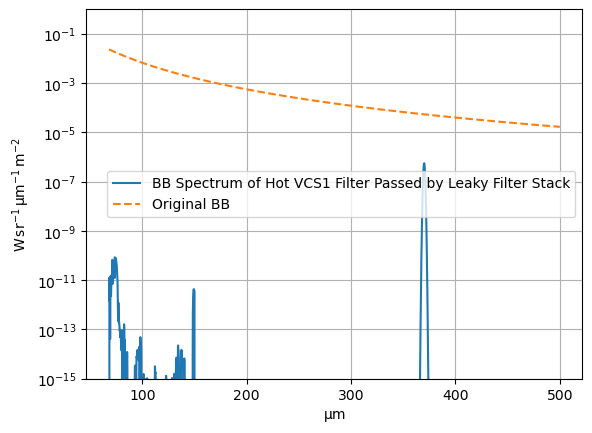

In [66]:
# What are detectors behind a hot VCS1 filter potentially seeing through the
# remaining filter stack?
fig, ax = plt.subplots()
ax.plot(
    lambd,
    (epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(filter_VCS1_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd)),
    label='BB Spectrum of Hot VCS1 Filter Passed by Leaky Filter Stack'
)
ax.plot(lambd, BlackBody(140 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd), ls='--', label='Original BB')
ax.legend()
ax.grid()
ax.set_yscale('log')
ax.set_ylim(1e-15, 1)

In [67]:
# what is the average inband transmission of the stack, as-measured?
inband = (lambd > 317 * u.um) & (lambd < (420 * u.um))
(bp_c7p5_single * bp_c7p5_single * bp_33icm * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating)[inband].mean()

np.float64(0.5299474082800586)

What kind of **entire-band** (LW) power reduction is available if our intermediate stage filters are cooler?

In [ ]:
# Assume the no-load case, but this load is common to both configs and drops out.
room_bb = 0

# - the window (rear) emits directly into the beam and is attenuated by filters
window_power_rear = (area * coeff_solid_angle * np.trapezoid(
    epsilon_hdpe(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(room_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# the 160 K stage special thermal should be largely transmissive in band, but
# may appear more black out of band due to the AR coating layer. this radiation
# is only attenuated by filters further down the stack. Because it is poorly
# conductive, the center is closer to equilibirum with the stage above (based on
# optics tube thermal sims)
st2_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(240 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# same for 60 K stage special thermal
st1_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bp_100icm * bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
    BlackBody(140 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# same for 4 K stage LPE
lpe_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
    BlackBody(45 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

total_power_warm_filters = (
    0 +
    window_power_rear +
    st2_power +
    st1_power +
    lpe_power +
    0
)
print('warm filter power:', total_power_warm_filters)


room_bb = 0

# - the window (rear) emits directly into the beam and is attenuated by filters
window_power_rear = (area * coeff_solid_angle * np.trapezoid(
    epsilon_hdpe(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(room_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# the 160 K stage special thermal should be largely transmissive in band, but
# may appear more black out of band due to the AR coating layer. this radiation
# is only attenuated by filters further down the stack. Because it is poorly
# conductive, the center is closer to equilibirum with the stage above (based on
# optics tube thermal sims)
st2_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(160 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# same for 60 K stage special thermal
st1_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bp_100icm * bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
    BlackBody(60 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

# same for 4 K stage LPE
lpe_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
    BlackBody(4 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

total_power_cold_filters = (
    0 +
    window_power_rear +
    st2_power +
    st1_power +
    lpe_power +
    0
)
print('cold filter power:', total_power_cold_filters)

print('reduction in power from having 160K, 60K, 4K filters at intended temperatures:', (total_power_warm_filters - total_power_cold_filters).to(u.pW))

warm filter power 67.64003505134717 pW
cold filter power 47.170094227233456 pW
reduction in power from having 160K, 60K, 4K filters at intended temperatures 20.469940824113714 pW


What about for just a single channel?

In [74]:
room_bb = 0

window_power_rear = (area * coeff_solid_angle * np.trapezoid(
    epsilon_hdpe(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(room_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

st2_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(240 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

st1_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_100icm * bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
    BlackBody(140 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

lpe_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
    BlackBody(45 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

total_power_warm_filters = (
    0 +
    window_power_rear +
    st2_power +
    st1_power +
    lpe_power +
    0
)
print('warm filter power:', total_power_warm_filters)


room_bb = 0

window_power_rear = (area * coeff_solid_angle * np.trapezoid(
    epsilon_hdpe(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(room_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

st2_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
    BlackBody(160 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

st1_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_100icm * bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
    BlackBody(60 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

lpe_power = (area * coeff_solid_angle * np.trapezoid(
    epsilon_specialthermal(lambd) *
    bandpass_feedhorn_lw(lambd) *
    bandpass_spec_channel(lambd, center_lambd) *
    bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
    BlackBody(4 * u.K, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
    (lambd ** 2),
    lambd
)).to(u.pW)

total_power_cold_filters = (
    0 +
    window_power_rear +
    st2_power +
    st1_power +
    lpe_power +
    0
)
print('cold filter power:', total_power_cold_filters)

print('reduction in power from having 160K, 60K, 4K filters at intended temperatures:', (total_power_warm_filters - total_power_cold_filters).to(u.fW))

warm filter power: 0.7438472879432892 pW
cold filter power: 0.5213171264348903 pW
reduction in power from having 160K, 60K, 4K filters at intended temperatures: 222.53016150839898 fW


### However, we do not know the emissivity or temperatures of our filters very well. What if they're more or less emissive, or more or less hot?

In [83]:
# Vary assumptions: emissivity of special thermals
st_emissivity_factors = np.linspace(0.01, 3, num=10)
bb_temps = np.arange(4, 100, 4) * u.K

ff, tt = np.meshgrid(st_emissivity_factors, bb_temps, indexing='ij')
powers = np.zeros_like(ff) * u.pW

for i, factor in enumerate(st_emissivity_factors):
    for j, bb_temp in enumerate(bb_temps):
        room_bb = (area * coeff_solid_angle * np.trapezoid(
            1.0 *
            bandpass_feedhorn_lw(lambd) *
            bandpass_spec_channel(lambd, center_lambd) *
            bp_hdpe * bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
            BlackBody(bb_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
            (lambd ** 2),
            lambd
        )).to(u.pW)

        # 3 similar contributions:
        # - the window (rear) emits directly into the beam and is attenuated by filters
        window_power_rear = (area * coeff_solid_angle * np.trapezoid(
            epsilon_hdpe(lambd) *
            bandpass_feedhorn_lw(lambd) *
            bandpass_spec_channel(lambd, center_lambd) *
            bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
            BlackBody(room_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
            (lambd ** 2),
            lambd
        )).to(u.pW)

        # the 160 K stage special thermal should be largely transmissive in band, but
        # may appear more black out of band due to the AR coating layer. this radiation
        # is only attenuated by filters further down the stack. Because it is poorly
        # conductive, the center is closer to equilibirum with the stage above (based on
        # optics tube thermal sims)
        st2_power = (area * coeff_solid_angle * np.trapezoid(
            epsilon_specialthermal(lambd) * factor *
            bandpass_feedhorn_lw(lambd) *
            bandpass_spec_channel(lambd, center_lambd) *
            bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
            BlackBody(filter_VCS2_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
            (lambd ** 2),
            lambd
        )).to(u.pW)

        # same for 60 K stage special thermal
        st1_power = (area * coeff_solid_angle * np.trapezoid(
            epsilon_specialthermal(lambd) * factor *
            bandpass_feedhorn_lw(lambd) *
            bandpass_spec_channel(lambd, center_lambd) *
            bp_100icm * bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
            BlackBody(filter_VCS1_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
            (lambd ** 2),
            lambd
        )).to(u.pW)

        total_power = (
            room_bb +
            window_power_rear +
            st2_power +
            st1_power +
            0
        )
        # print(total_power)
        powers[i][j] = total_power

Text(0.5, 0, 'External Blackbody Temp. (K)')

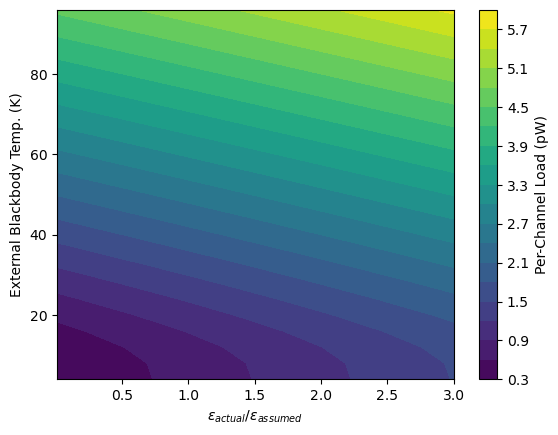

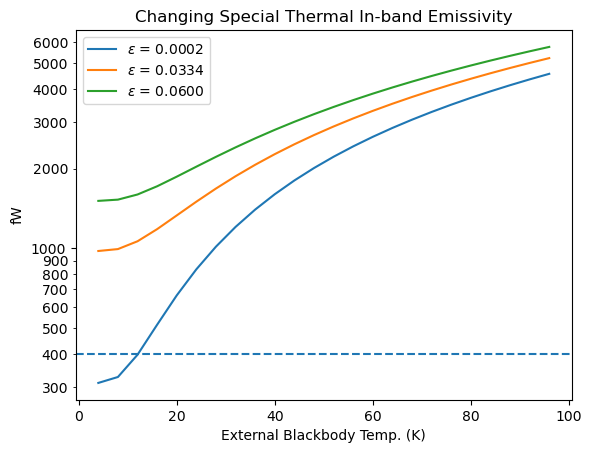

In [84]:
from matplotlib.ticker import FormatStrFormatter

fig, ax = plt.subplots()
im = ax.contourf(ff, tt, powers.value, levels=20)
fig.colorbar(im, ax=ax, label='Per-Channel Load (pW)')
ax.set_xlabel('$\epsilon_{actual} / \epsilon_{assumed}$')
ax.set_ylabel('External Blackbody Temp. (K)')

fig, ax = plt.subplots()
for row in [0, ff.shape[0]//2, -1]:
    s = np.s_[row,:]
    ax.semilogy(tt[s], powers[s].to(u.fW), label=f'$\epsilon$ = {0.02 * ff[s].mean():.4f}')
ax.set_title('Changing Special Thermal In-band Emissivity')
ax.axhline(.4 * u.pW, ls='--')
ax.legend()
ax.yaxis.set_minor_formatter(FormatStrFormatter("%.0f"))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.0f"))
ax.set_xlabel('External Blackbody Temp. (K)')

In [80]:
# Vary assumptions: temperature of VCS filters
filter_temp_factors = np.linspace(0.5, 1, num=10)
bb_temps = np.arange(4, 100, 4) * u.K

ff, tt = np.meshgrid(filter_temp_factors, bb_temps, indexing='ij')
powers = np.zeros_like(ff) * u.pW

for i, factor in enumerate(filter_temp_factors):
    for j, bb_temp in enumerate(bb_temps):
        room_bb = (area * coeff_solid_angle * np.trapezoid(
            1.0 *
            bandpass_feedhorn_lw(lambd) *
            bandpass_spec_channel(lambd, center_lambd) *
            bp_hdpe * bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
            BlackBody(bb_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
            (lambd ** 2),
            lambd
        )).to(u.pW)

        # 3 similar contributions:
        # - the window (rear) emits directly into the beam and is attenuated by filters
        window_power_rear = (area * coeff_solid_angle * np.trapezoid(
            epsilon_hdpe(lambd) *
            bandpass_feedhorn_lw(lambd) *
            bandpass_spec_channel(lambd, center_lambd) *
            bp_c7p5_single * bp_c7p5_double * bp_VCS2_st * bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
            BlackBody(room_temp, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
            (lambd ** 2),
            lambd
        )).to(u.pW)

        # the 160 K stage special thermal should be largely transmissive in band, but
        # may appear more black out of band due to the AR coating layer. this radiation
        # is only attenuated by filters further down the stack. Because it is poorly
        # conductive, the center is closer to equilibirum with the stage above (based on
        # optics tube thermal sims)
        st2_power = (area * coeff_solid_angle * np.trapezoid(
            epsilon_specialthermal(lambd) *
            bandpass_feedhorn_lw(lambd) *
            bandpass_spec_channel(lambd, center_lambd) *
            bp_VCS1_st * bp_100icm * bp_60icm * bp_33icm * bp_42icm * eff_blaze_grating *
            BlackBody(filter_VCS2_temp * factor, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
            (lambd ** 2),
            lambd
        )).to(u.pW)

        # same for 60 K stage special thermal
        st1_power = (area * coeff_solid_angle * np.trapezoid(
            epsilon_specialthermal(lambd) *
            bandpass_feedhorn_lw(lambd) *
            bandpass_spec_channel(lambd, center_lambd) *
            bp_100icm * bp_33icm * bp_60icm * bp_42icm * eff_blaze_grating *
            BlackBody(filter_VCS1_temp * factor, scale=(1 * u.W / u.m**2 / u.um / u.sr))(lambd) *
            (lambd ** 2),
            lambd
        )).to(u.pW)

        total_power = (
            room_bb +
            window_power_rear +
            st2_power +
            st1_power +
            0
        )
        # print(total_power)
        powers[i][j] = total_power

Text(0.5, 0, 'External Blackbody Temp. (K)')

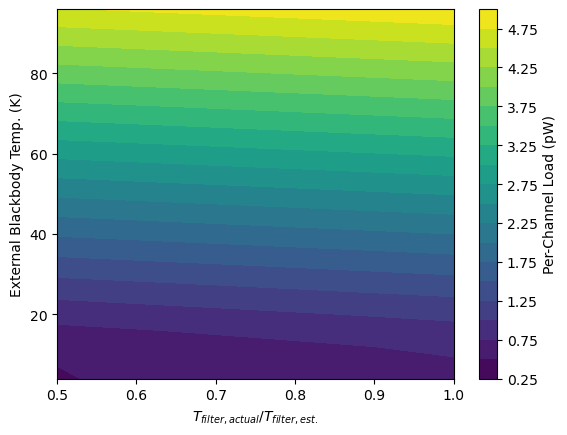

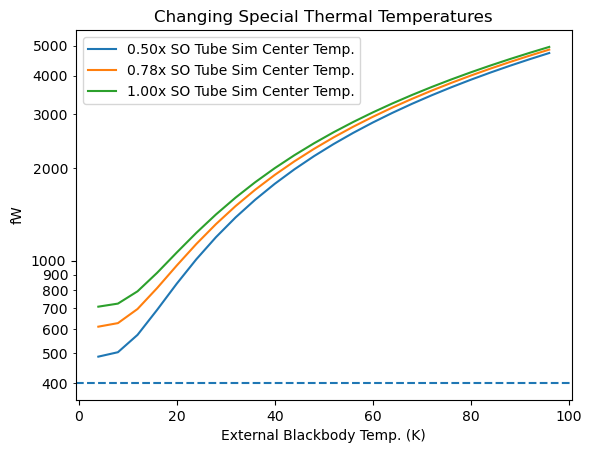

In [82]:
from matplotlib.ticker import FormatStrFormatter

fig, ax = plt.subplots()
im = ax.contourf(ff, tt, powers.value, levels=20)
fig.colorbar(im, ax=ax, label='Per-Channel Load (pW)')
ax.set_xlabel('$T_{filter, actual} / T_{filter,est.}$')
ax.set_ylabel('External Blackbody Temp. (K)')

fig, ax = plt.subplots()
for row in [0, ff.shape[0]//2, -1]:
    s = np.s_[row,:]
    ax.semilogy(tt[s], powers[s].to(u.fW), label=f'{ff[s].mean():.2f}x SO Tube Sim Center Temp.')
ax.set_title('Changing Special Thermal Temperatures')
ax.axhline(.4 * u.pW, ls='--')
ax.legend()
ax.yaxis.set_minor_formatter(FormatStrFormatter("%.0f"))
ax.yaxis.set_major_formatter(FormatStrFormatter("%.0f"))
ax.set_xlabel('External Blackbody Temp. (K)')

From these plots, we can get an idea of the diagnostic power of various blackbodies outside of the cryostat, in terms of discriminating between non-ideal filter properties.